<a href="https://colab.research.google.com/github/jsmak/dl-framework/blob/main/03_tensor/01_tensor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 텐서(Tensor)

텐서는 PyTorch에서 가장 기본이 되는 데이터 구조입니다.  
이번에는 텐서를 생성하거나, 텐서끼리 계산을 하는 코드를 연습합니다.

## 1. 텐서 생성

torch의 tensor 함수를 통해 텐서를 생성합니다.  
아래 셀에서는 Python 리스트로부터 텐서를 생성합니다.  
또한, type( )을 통해 타입을 확인합니다.

### 텐서의 차원(Dimension) 구조 시각화

텐서는 다차원 배열을 효율적으로 다루기 위한 PyTorch의 핵심 데이터 구조입니다. 아래 그림은 0차원 스칼라(Scalar)부터 3차원 텐서(3D Tensor)까지의 구조를 시각적으로 이해하기 쉽게 나타낸 것입니다.

<p align="center">
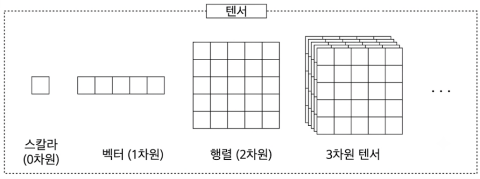
</p>

- **0차원 (스칼라, Scalar):** 단 하나의 숫자 값을 가집니다. (예: `3`)
- **1차원 (벡터, Vector):** 숫자들의 1차원 배열(선형 구조)입니다. (예: `[1, 2, 3, 4]`)
- **2차원 (행렬, Matrix):** 행(Row)과 열(Column)로 구성된 2차원 배열입니다. (예: `[[1, 2], [3, 4]]`)
- **3차원 이상 (텐서, Tensor):** 면, 행, 열을 가지는 다차원 구조로, 이미지나 고차원 데이터를 표현할 때 사용됩니다.

## 2. Tensor의 차원 정보 확인
- shape
- size()

Tensor의 차원 정보는 shape와 size()로 확인 가능합니다.   
둘다 동일한 값을 반환합니다.


In [1]:
import torch

# 0차원 텐서(스칼라)
print("0차원 텐서(스칼라)")
scalar = torch.tensor(3)
print(scalar, type(scalar))
print(scalar.shape, scalar.size(), scalar.dtype)
print("-" * 20)

# 1차원 텐서(벡터)
print("1차원 텐서(벡터)")
vector = torch.tensor([1, 2, 3, 4])
print(vector)
print(vector.shape, vector.size(), vector.dtype)
print("-" * 20)

# 2차원 텐서(행렬)
print("2차원 텐서(행렬)")
matrix = torch.tensor([[1, 2], [3, 4]])
print(matrix)
print(matrix.size(), matrix.dtype)
print("-" * 20)

# 3차원 텐서
print("3차원 텐서")
tensor3d = torch.tensor([[[1, 2], [3, 4]], [[5, 6], [7, 8]]])
print(tensor3d)
print(tensor3d.size(), tensor3d.dtype)

0차원 텐서(스칼라)
tensor(3) <class 'torch.Tensor'>
torch.Size([]) torch.Size([]) torch.int64
--------------------
1차원 텐서(벡터)
tensor([1, 2, 3, 4])
torch.Size([4]) torch.Size([4]) torch.int64
--------------------
2차원 텐서(행렬)
tensor([[1, 2],
        [3, 4]])
torch.Size([2, 2]) torch.int64
--------------------
3차원 텐서
tensor([[[1, 2],
         [3, 4]],

        [[5, 6],
         [7, 8]]])
torch.Size([2, 2, 2]) torch.int64


이 외에도 다양한 방법으로 텐서를 생성할 수 있습니다.

In [2]:
# 중첩 리스트로부터 생성
b = torch.tensor([[1, 2], [3, 4]])
print(b, b.dtype)

# dtype을 지정하여 배정밀도(double precision) Tensor로 변환
c = torch.tensor([[1, 2], [3, 4]], dtype=torch.float64)
print(c, c.dtype)

# 0부터 9까지의 수치로 초기화
d = torch.arange(0, 10)
print(d, d.dtype)

# 모든 값이 0인 2×3 크기의 Tensor
e = torch.zeros(2, 3)
print(e, e.dtype)

# 모든 값이 난수인 2×3 크기의 Tensor
f = torch.rand(2, 3)
print(f)

tensor([[1, 2],
        [3, 4]]) torch.int64
tensor([[1., 2.],
        [3., 4.]], dtype=torch.float64) torch.float64
tensor([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]) torch.int64
tensor([[0., 0., 0.],
        [0., 0., 0.]]) torch.float32
tensor([[0.8618, 0.1807, 0.6052],
        [0.8904, 0.9482, 0.9966]])


## 텐서와 NumPy 배열 간의 변환

numpy() 메서드로 텐서를 NumPy 배열로 변환할 수 있습니다.  
또한, from_numpy() 함수로 NumPy 배열을 텐서로 변환할 수 있습니다.

In [3]:
import numpy as np
# Tensor → NumPy
a = torch.tensor([[1., 2.], [3., 4.]])
b = a.numpy()
print(b, b.dtype)

# NumPy → Tensor
c = np.array([[1., 2.], [3., 4.]])
d = torch.from_numpy(c)
print(d, d.dtype)

[[1. 2.]
 [3. 4.]] float32
tensor([[1., 2.],
        [3., 4.]], dtype=torch.float64) torch.float64


## 인덱싱과 슬라이싱

넘파이 배열처럼 인덱싱과 슬라이싱을 사용해 텐서에 접근할 수 있습니다.

In [4]:
a = torch.tensor([[1, 2, 3], [4, 5, 6]])

# 2개의 인덱스를 지정
print(a[0, 1])

# 범위를 지정
print(a[1:2, :2])

# 리스트로 여러 인덱스를 지정
print(a[:, [0, 2]])

# 3보다 큰 요소만 지정
print(a[a>3])

# 요소 변경
a[0, 2] = 11
print(a)

# 요소를 일괄 변경
a[:, 1] = 22
print(a)

# 10보다 큰 요소만 변경
a[a>10] = 33
print(a)

tensor(2)
tensor([[4, 5]])
tensor([[1, 3],
        [4, 6]])
tensor([4, 5, 6])
tensor([[ 1,  2, 11],
        [ 4,  5,  6]])
tensor([[ 1, 22, 11],
        [ 4, 22,  6]])
tensor([[ 1, 33, 33],
        [ 4, 33,  6]])


## 텐서 연산

텐서를 통해 벡터나 행렬을 표현할 수 있습니다.  
이러한 연산은 일정한 규칙에 따라 수행됩니다.

In [5]:
# 벡터
a = torch.tensor([1, 2, 3])
b = torch.tensor([4, 5, 6])

# 행렬
c = torch.tensor([[6, 5, 4],
                  [3, 2, 1]])

# 벡터와 스칼라 연산
print(a + 3)

# 벡터끼리의 연산
print(a + b)

# 행렬과 스칼라 연산
print(c + 2)

# 행렬과 벡터의 연산 (브로드캐스팅)
print(c + a)

# 행렬끼리의 연산
print(c + c)

tensor([4, 5, 6])
tensor([5, 7, 9])
tensor([[8, 7, 6],
        [5, 4, 3]])
tensor([[7, 7, 7],
        [4, 4, 4]])
tensor([[12, 10,  8],
        [ 6,  4,  2]])


## 다양한 값의 계산

평균값, 합계, 최댓값, 최솟값 등 다양한 값을 계산하는 함수와 메서드가 제공됩니다.

In [6]:
a = torch.tensor([[1, 2, 3], [4, 5, 6.]])

# 평균값을 구하는 함수
m = torch.mean(a)
print(m)
print(m.item())  # item()으로 값을 꺼냄

# 평균값을 구하는 메서드
m = a.mean()
print(m.item())

# 열 기준 평균값
print(a.mean(0))

# 행 기준 평균값
print(a.mean(1))

# 합계
print(torch.sum(a).item())

# 최댓값
print(torch.max(a).item())

# 최솟값
print(torch.min(a).item())

tensor(3.5000)
3.5
3.5
tensor([2.5000, 3.5000, 4.5000])
tensor([2., 5.])
21.0
6.0
1.0
